In [15]:
import numpy as np

In [11]:
import pandas as pd

# Data Processing
patients = pd.read_csv('patients.csv')
diagnoses = pd.read_csv('diagnoses.csv')
outcomes = pd.read_csv("outcomes.csv")
labs = pd.read_csv("labs.csv")

In [12]:
patients = patients.merge(diagnoses, on = 'DiagnosisID')
patients = patients.merge(outcomes, on = 'OutcomeID')

In [13]:
patients['AdmissionDate'] = pd.to_datetime(patients['AdmissionDate'])
patients['DischargeDate'] = pd.to_datetime(patients['DischargeDate'])
patients['LengthOfStay'] = (patients['DischargeDate'] - patients['AdmissionDate']).dt.days


In [14]:
patients['OutcomeEmcoded'] = patients['OutcomeName'].map({'Recovered' : 0, 'Complicated' : 1, 'Deceased': 1})

In [16]:
patients['HighRisk'] = np.where((patients['Age'] > 65) | (patients['OutcomeName'].isin(['Complicated', 'Deceased'])), 1, 0)

In [18]:
abnormal_conditions = {
    'Blood Sugar': lambda x: x > 120,
    'Cholestrol': lambda x: x > 200,
    'Hemoglobin': lambda x: x < 13
}

def count_abnormal_labs(patients_id):
    patients_labs = labs[labs['PatientID'] == patients_id]
    count = 0
    for test_name, condition in abnormal_conditions.items():
        test_results = patients_labs[patients_labs['TestName'] == test_name]
        count += test_results['Result'].apply(condition).sum()
    return count

patients['AbnormalLabsCount'] = patients['PatientID'].apply(count_abnormal_labs)

Model Training

In [28]:
features = patients[['Age', 'LengthOfStay', 'TreatmentCost']]
target = patients['OutcomeEmcoded']

In [29]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(features, target, test_size= 0.3, random_state= 42)

In [30]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter = 500)
model.fit(X_train, Y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,500
,multi_class,'deprecated'


In [31]:
from sklearn.metrics import classification_report, confusion_matrix
Y_pred = model.predict(X_test)
print("Classification Report:")
print(classification_report(Y_test, Y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        17
           1       0.72      1.00      0.83        43

    accuracy                           0.72        60
   macro avg       0.36      0.50      0.42        60
weighted avg       0.51      0.72      0.60        60



d:\TuteDude\Anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\TuteDude\Anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\TuteDude\Anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


ROC Curve

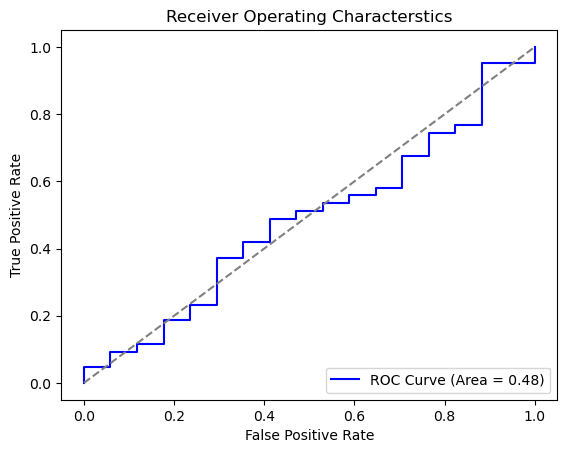

In [32]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

Y_prob = model.predict_proba(X_test)[:,1]
fpr, tpr, threshold = roc_curve(Y_test, Y_prob)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color = 'blue', label = f'ROC Curve (Area = {roc_auc:.2f})')
plt.plot([0,1], [0,1], color = 'gray', linestyle = '--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characterstics')
plt.legend(loc="lower right")
plt.show()

In [33]:
import joblib
joblib.dump(model, 'Risk_Modal.ipynb')

['Risk_Modal.ipynb']